# Análisis exploratorio — House Prices

Primera exploración del dataset *House Prices: Advanced Regression Techniques* (Kaggle).

**Objetivo:** entender la variable objetivo `SalePrice`, el estado de los datos (faltantes, tipos)
y qué variables se relacionan más con el precio, para alimentar el feature engineering en
`house_pricing/features.py`.

**Datos:** `data/raw/train.csv` (1460 filas) y `data/raw/test.csv`.

## 0. Configuración

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# Rutas del proyecto. Si el paquete aún no está instalado (`make requirements`),
# caemos a rutas relativas al notebook.
try:
    from house_pricing.config import FIGURES_DIR, RAW_DATA_DIR
except ModuleNotFoundError:
    PROJ_ROOT = Path.cwd().parent
    RAW_DATA_DIR = PROJ_ROOT / "data" / "raw"
    FIGURES_DIR = PROJ_ROOT / "reports" / "figures"

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

print("Datos crudos:", RAW_DATA_DIR)

Datos crudos: C:\Users\dgarc\OneDrive\Escritorio\Maestria\4T_2026\Product_Mang\Clase_Cloud\house_pricing\data\raw


In [3]:
# Paleta y estilo: marcas delgadas, rejilla discreta, sin bordes superfluos.
SURFACE = "#fcfcfb"
INK = "#0b0b0b"
INK_MUTED = "#52514e"
GRID = "#e5e4e0"
BLUE = "#2a78d6"  # serie única / escala secuencial
RED = "#e34948"  # polo opuesto en la escala divergente
NEUTRAL = "#f0efec"  # punto medio neutro

# Divergente azul <-> rojo con gris al centro: para correlaciones, donde el signo importa.
CMAP_DIV = LinearSegmentedColormap.from_list("div_blue_red", [BLUE, NEUTRAL, RED])

plt.rcParams.update(
    {
        "figure.figsize": (8, 4.5),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_MUTED,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.titlepad": 12,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_MUTED,
        "ytick.color": INK_MUTED,
        "text.color": INK,
        "font.size": 9,
        "lines.linewidth": 2,
    }
)

In [4]:
# 'NA' en este dataset es un valor real (p. ej. Alley = sin callejón), no un dato perdido,
# pero Kaggle lo escribe igual que un faltante. Lo leemos como NaN y lo documentamos.
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")

print("train:", train.shape)
print("test: ", test.shape)
print("columnas solo en train:", set(train.columns) - set(test.columns))

train: (1460, 81)
test:  (1459, 80)
columnas solo en train: {'SalePrice'}


## 1. Vistazo general

In [5]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,Wd Sdng,Wd Shng,NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [6]:
num_cols = train.select_dtypes(include="number").columns.drop(["Id", "SalePrice"])
cat_cols = train.select_dtypes(exclude="number").columns

print(f"numéricas:   {len(num_cols)}")
print(f"categóricas: {len(cat_cols)}")
print(f"duplicados:  {train.duplicated(subset=train.columns.drop('Id')).sum()}")

train.dtypes.value_counts().to_frame("columnas")

numéricas:   36
categóricas: 43
duplicados:  0


,columnas
str,43
int64,35
float64,3


## 2. Variable objetivo: `SalePrice`

La métrica oficial de la competencia es RMSE sobre `log(SalePrice)`, así que vale la pena
comprobar de entrada qué tan sesgada está la distribución y si el log la normaliza.

In [7]:
y = train["SalePrice"]

resumen = y.describe()[["mean", "std", "min", "25%", "50%", "75%", "max"]]
resumen["skew"] = y.skew()
resumen["kurtosis"] = y.kurtosis()
resumen.to_frame("SalePrice").style.format("{:,.2f}")

,SalePrice
mean,"180,921.20"
std,"79,442.50"
min,"34,900.00"
25%,"129,975.00"
50%,"163,000.00"
75%,"214,000.00"
max,"755,000.00"
skew,1.88
kurtosis,6.54


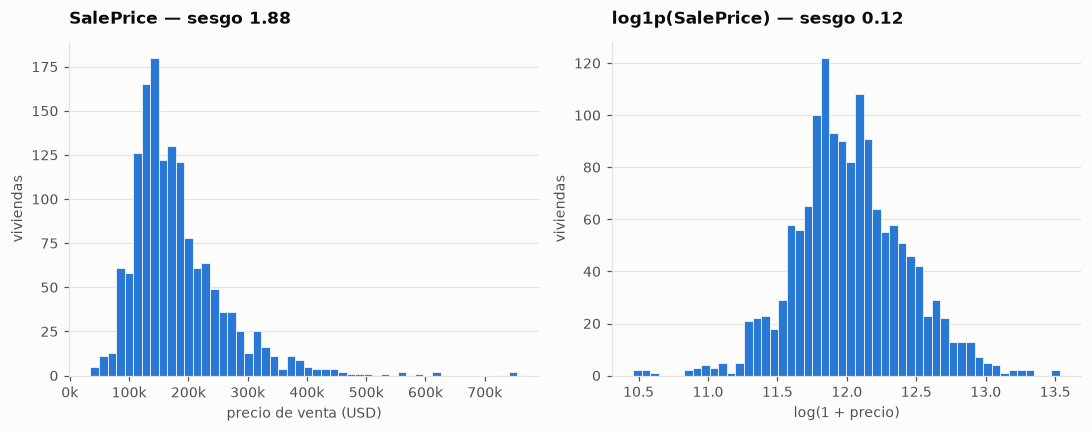

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].hist(y, bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[0].set_title(f"SalePrice — sesgo {y.skew():.2f}")
axes[0].set_xlabel("precio de venta (USD)")
axes[0].xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")

axes[1].hist(np.log1p(y), bins=50, color=BLUE, edgecolor=SURFACE, linewidth=0.5)
axes[1].set_title(f"log1p(SalePrice) — sesgo {np.log1p(y).skew():.2f}")
axes[1].set_xlabel("log(1 + precio)")

for ax in axes:
    ax.set_ylabel("viviendas")
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

fig.tight_layout()

## 3. Valores faltantes

Ojo con la trampa del dataset: muchos `NaN` son **ausencia de la característica**, no datos
perdidos. `PoolQC` nulo significa "sin piscina"; `GarageType` nulo, "sin garaje". El
`data_description.txt` en `data/raw/` lo confirma columna por columna.

In [9]:
def tabla_faltantes(df: pd.DataFrame) -> pd.DataFrame:
    n = df.isna().sum()
    n = n[n > 0].sort_values(ascending=False)
    return pd.DataFrame({"faltantes": n, "pct": (n / len(df) * 100).round(1), "dtype": df.dtypes[n.index]})


faltantes_train = tabla_faltantes(train)
print(f"{len(faltantes_train)} columnas con faltantes en train")
faltantes_train

19 columnas con faltantes en train


,faltantes,pct,dtype
PoolQC,1453,99.5,str
MiscFeature,1406,96.3,str
Alley,1369,93.8,str
Fence,1179,80.8,str
MasVnrType,872,59.7,str
FireplaceQu,690,47.3,str
LotFrontage,259,17.7,float64
GarageType,81,5.5,str
GarageYrBlt,81,5.5,float64
GarageFinish,81,5.5,str


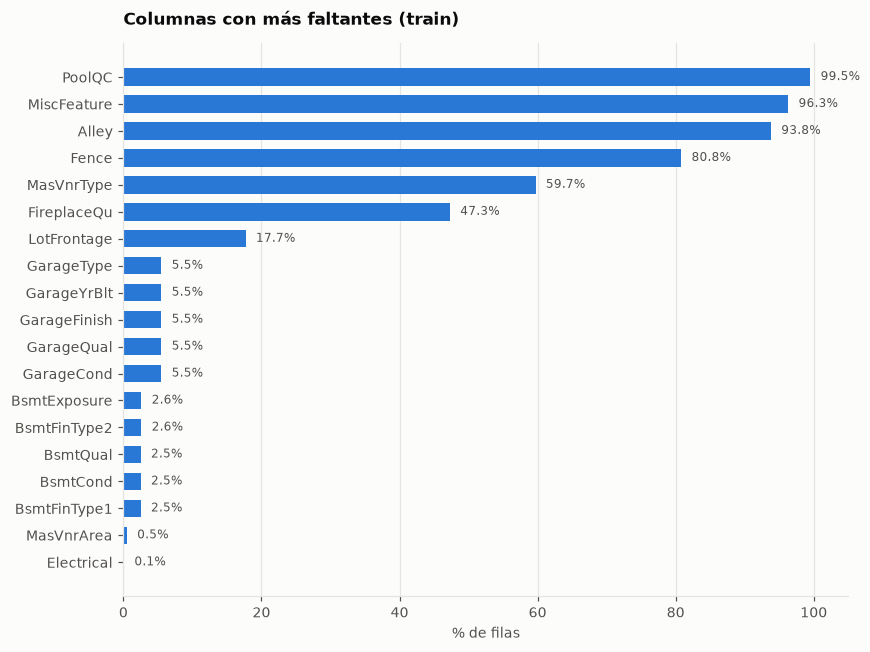

In [10]:
top = faltantes_train.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top.index, top["pct"], color=BLUE, height=0.65)
ax.set_title("Columnas con más faltantes (train)")
ax.set_xlabel("% de filas")
ax.set_xlim(0, 105)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

# Etiqueta directa en cada barra: 20 valores legibles, mejor que leerlos del eje.
for nombre, pct in top["pct"].items():
    ax.text(pct + 1.5, nombre, f"{pct:.1f}%", va="center", fontsize=8, color=INK_MUTED)

fig.tight_layout()

In [11]:
# Comparar train vs test: una columna que solo falta en test nos obligaría a imputar en producción.
comparacion = pd.DataFrame(
    {"train_pct": train.isna().mean() * 100, "test_pct": test.isna().mean() * 100}
).round(1)
comparacion = comparacion[(comparacion > 0).any(axis=1)]
comparacion["solo_en_test"] = (comparacion["train_pct"] == 0) & (comparacion["test_pct"] > 0)
comparacion.sort_values("test_pct", ascending=False)

,train_pct,test_pct,solo_en_test
PoolQC,99.5,99.8,False
MiscFeature,96.3,96.5,False
Alley,93.8,92.7,False
Fence,80.8,80.1,False
MasVnrType,59.7,61.3,False
FireplaceQu,47.3,50.0,False
LotFrontage,17.7,15.6,False
GarageFinish,5.5,5.3,False
GarageCond,5.5,5.3,False
GarageYrBlt,5.5,5.3,False


## 4. Variables numéricas frente al precio

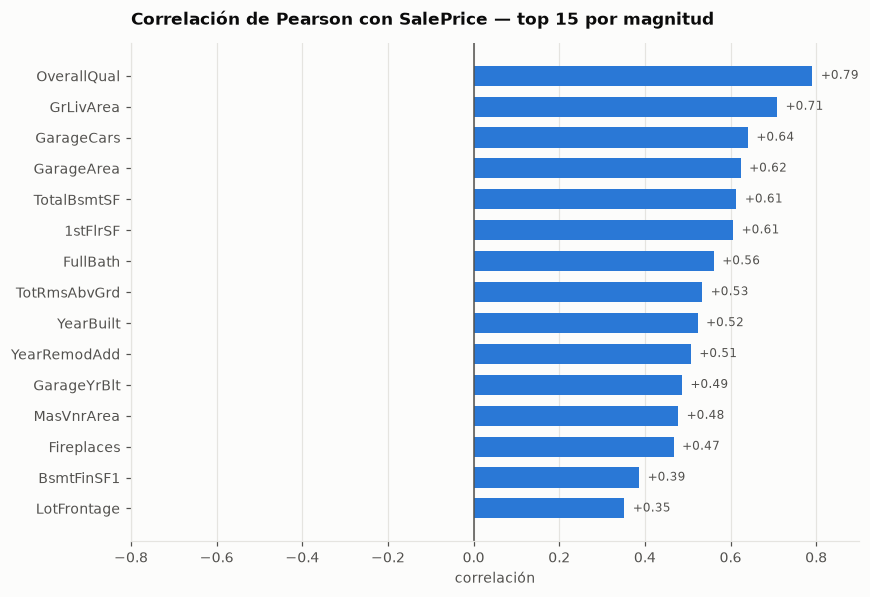

In [12]:
corr_objetivo = train[num_cols.tolist() + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice")
top_corr = corr_objetivo.abs().sort_values(ascending=False).head(15).index
orden = corr_objetivo[top_corr].sort_values()

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(orden.index, orden.values, color=[RED if v < 0 else BLUE for v in orden.values], height=0.65)
ax.axvline(0, color=INK_MUTED, linewidth=1)
ax.set_title("Correlación de Pearson con SalePrice — top 15 por magnitud")
ax.set_xlabel("correlación")
ax.set_xlim(-0.8, 0.9)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

for nombre, v in orden.items():
    desplazamiento = 0.02 if v >= 0 else -0.02
    ax.text(
        v + desplazamiento,
        nombre,
        f"{v:+.2f}",
        va="center",
        ha="left" if v >= 0 else "right",
        fontsize=8,
        color=INK_MUTED,
    )

fig.tight_layout()

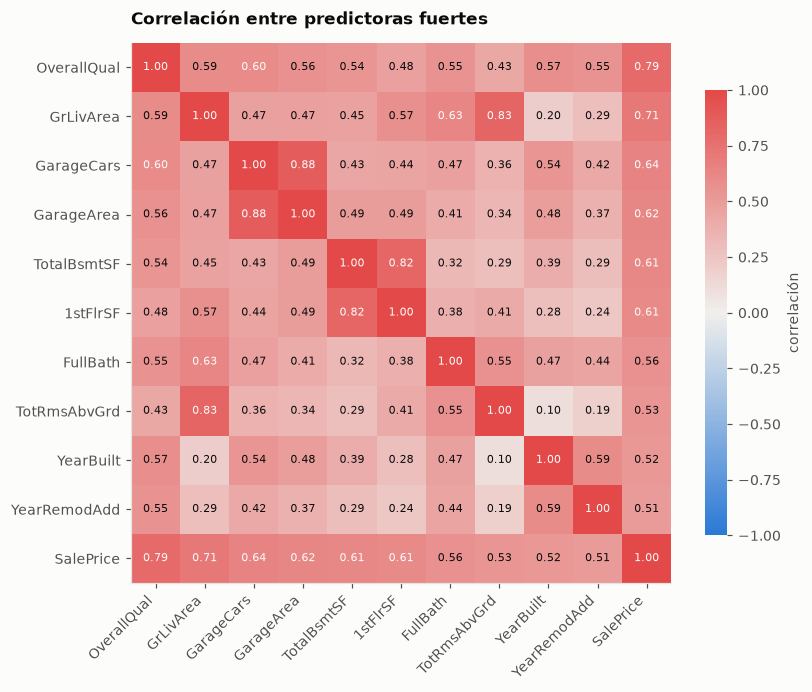

In [13]:
# Matriz entre las predictoras fuertes: busca redundancia (p. ej. GarageCars vs GarageArea).
cols_matriz = corr_objetivo.abs().sort_values(ascending=False).head(10).index.tolist() + ["SalePrice"]
m = train[cols_matriz].corr()

fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(m, cmap=CMAP_DIV, vmin=-1, vmax=1)
ax.set_xticks(range(len(m)), m.columns, rotation=45, ha="right")
ax.set_yticks(range(len(m)), m.columns)
ax.set_title("Correlación entre predictoras fuertes")
ax.grid(visible=False)

for i in range(len(m)):
    for j in range(len(m)):
        v = m.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color=INK if abs(v) < 0.6 else SURFACE)

cbar = fig.colorbar(im, ax=ax, shrink=0.75)
cbar.set_label("correlación", color=INK_MUTED)
cbar.outline.set_visible(False)
fig.tight_layout()

,Id,GrLivArea,OverallQual,SaleCondition,SalePrice
523,524,4676,10,Partial,184750
1298,1299,5642,10,Partial,160000


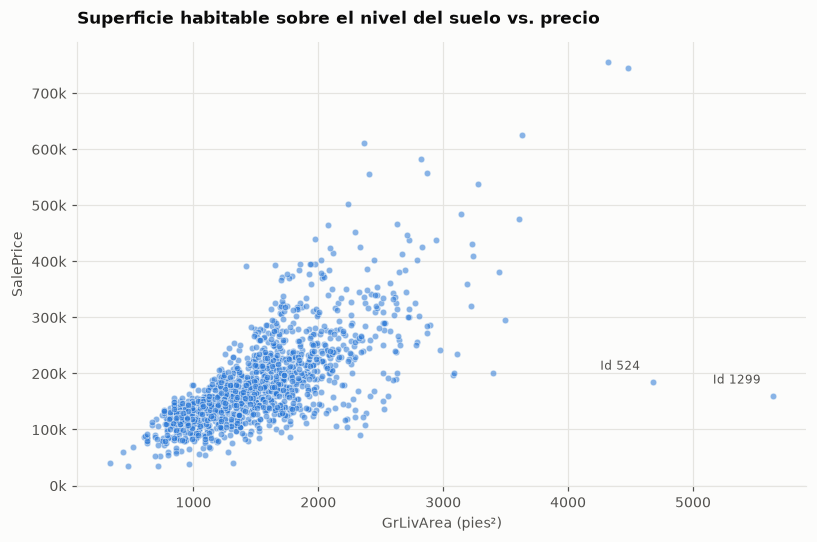

In [14]:
# GrLivArea es la predictora continua más fuerte. El scatter revela los outliers célebres
# del dataset: casas enormes vendidas baratas (ventas parciales/familiares).
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.scatter(train["GrLivArea"], y, s=18, color=BLUE, alpha=0.55, edgecolor=SURFACE, linewidth=0.5)
ax.set_title("Superficie habitable sobre el nivel del suelo vs. precio")
ax.set_xlabel("GrLivArea (pies²)")
ax.set_ylabel("SalePrice")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_axisbelow(True)

sospechosos = train[(train["GrLivArea"] > 4000) & (y < 300_000)]
for _, fila in sospechosos.iterrows():
    ax.annotate(
        f"Id {int(fila['Id'])}",
        (fila["GrLivArea"], fila["SalePrice"]),
        textcoords="offset points",
        xytext=(-8, 8),
        ha="right",
        fontsize=8,
        color=INK_MUTED,
    )

fig.tight_layout()
sospechosos[["Id", "GrLivArea", "OverallQual", "SaleCondition", "SalePrice"]]

## 4.1 Separar las numéricas en discretas y continuas

Los scatter anteriores salían a rayas en varias variables: no es un defecto del gráfico, es
que esas variables solo toman unos pocos valores enteros (`GarageCars` vale 0, 1, 2, 3 o 4).
Un scatter de una variable así solo muestra columnas apiladas y esconde la distribución.

La regla de corte es la cardinalidad: **15 valores distintos o menos → discreta**. El umbral
no es arbitrario; en este dataset hay un salto limpio entre `MSSubClass` (15 valores) y
`YearRemodAdd` (61), así que cualquier corte en ese hueco separa lo mismo.

Cada grupo va a su gráfico: las continuas siguen con scatter (4.2) y las discretas pasan a
boxplot con los puntos encima (4.3).

In [15]:
UMBRAL_DISCRETA = 15

cardinalidad = train[num_cols].nunique().sort_values()
discretas = cardinalidad[cardinalidad <= UMBRAL_DISCRETA].index.tolist()
continuas = cardinalidad[cardinalidad > UMBRAL_DISCRETA].index.tolist()

# Correlación con el precio: sirve para ordenar los paneles en 4.2 y 4.3.
corrs = train[num_cols.tolist() + ["SalePrice"]].corr()["SalePrice"].drop("SalePrice")

grupos = pd.DataFrame(
    {
        "valores_distintos": cardinalidad,
        "grupo": np.where(cardinalidad <= UMBRAL_DISCRETA, "discreta", "continua"),
        "correlacion": corrs.reindex(cardinalidad.index).round(3),
    }
)

print(f"discretas: {len(discretas)}  ·  continuas: {len(continuas)}  ·  total: {len(num_cols)}")
grupos


discretas: 15  ·  continuas: 21  ·  total: 36


,valores_distintos,grupo,correlacion
HalfBath,3,discreta,0.284
BsmtHalfBath,3,discreta,-0.017
FullBath,4,discreta,0.561
BsmtFullBath,4,discreta,0.227
Fireplaces,4,discreta,0.467
KitchenAbvGr,4,discreta,-0.136
GarageCars,5,discreta,0.640
YrSold,5,discreta,-0.029
PoolArea,8,discreta,0.092
BedroomAbvGr,8,discreta,0.168


## 4.2 Scatter de las variables continuas

Las mismas gráficas de antes, ahora solo con las continuas, que es donde un scatter dice
algo. En el título va el nombre de la variable y su correlación de Pearson (`r`), y encima se
traza una línea de tendencia para ver si la relación es lineal, curva o inexistente.

Los paneles van ordenados por `|r|` de mayor a menor y comparten el eje vertical, así que las
alturas son comparables entre paneles.

21 variables continuas · 6x4 paneles


,correlacion,abs_correlacion
GrLivArea,0.709,0.709
GarageArea,0.623,0.623
TotalBsmtSF,0.614,0.614
1stFlrSF,0.606,0.606
YearBuilt,0.523,0.523
YearRemodAdd,0.507,0.507
GarageYrBlt,0.486,0.486
MasVnrArea,0.477,0.477
BsmtFinSF1,0.386,0.386
LotFrontage,0.352,0.352


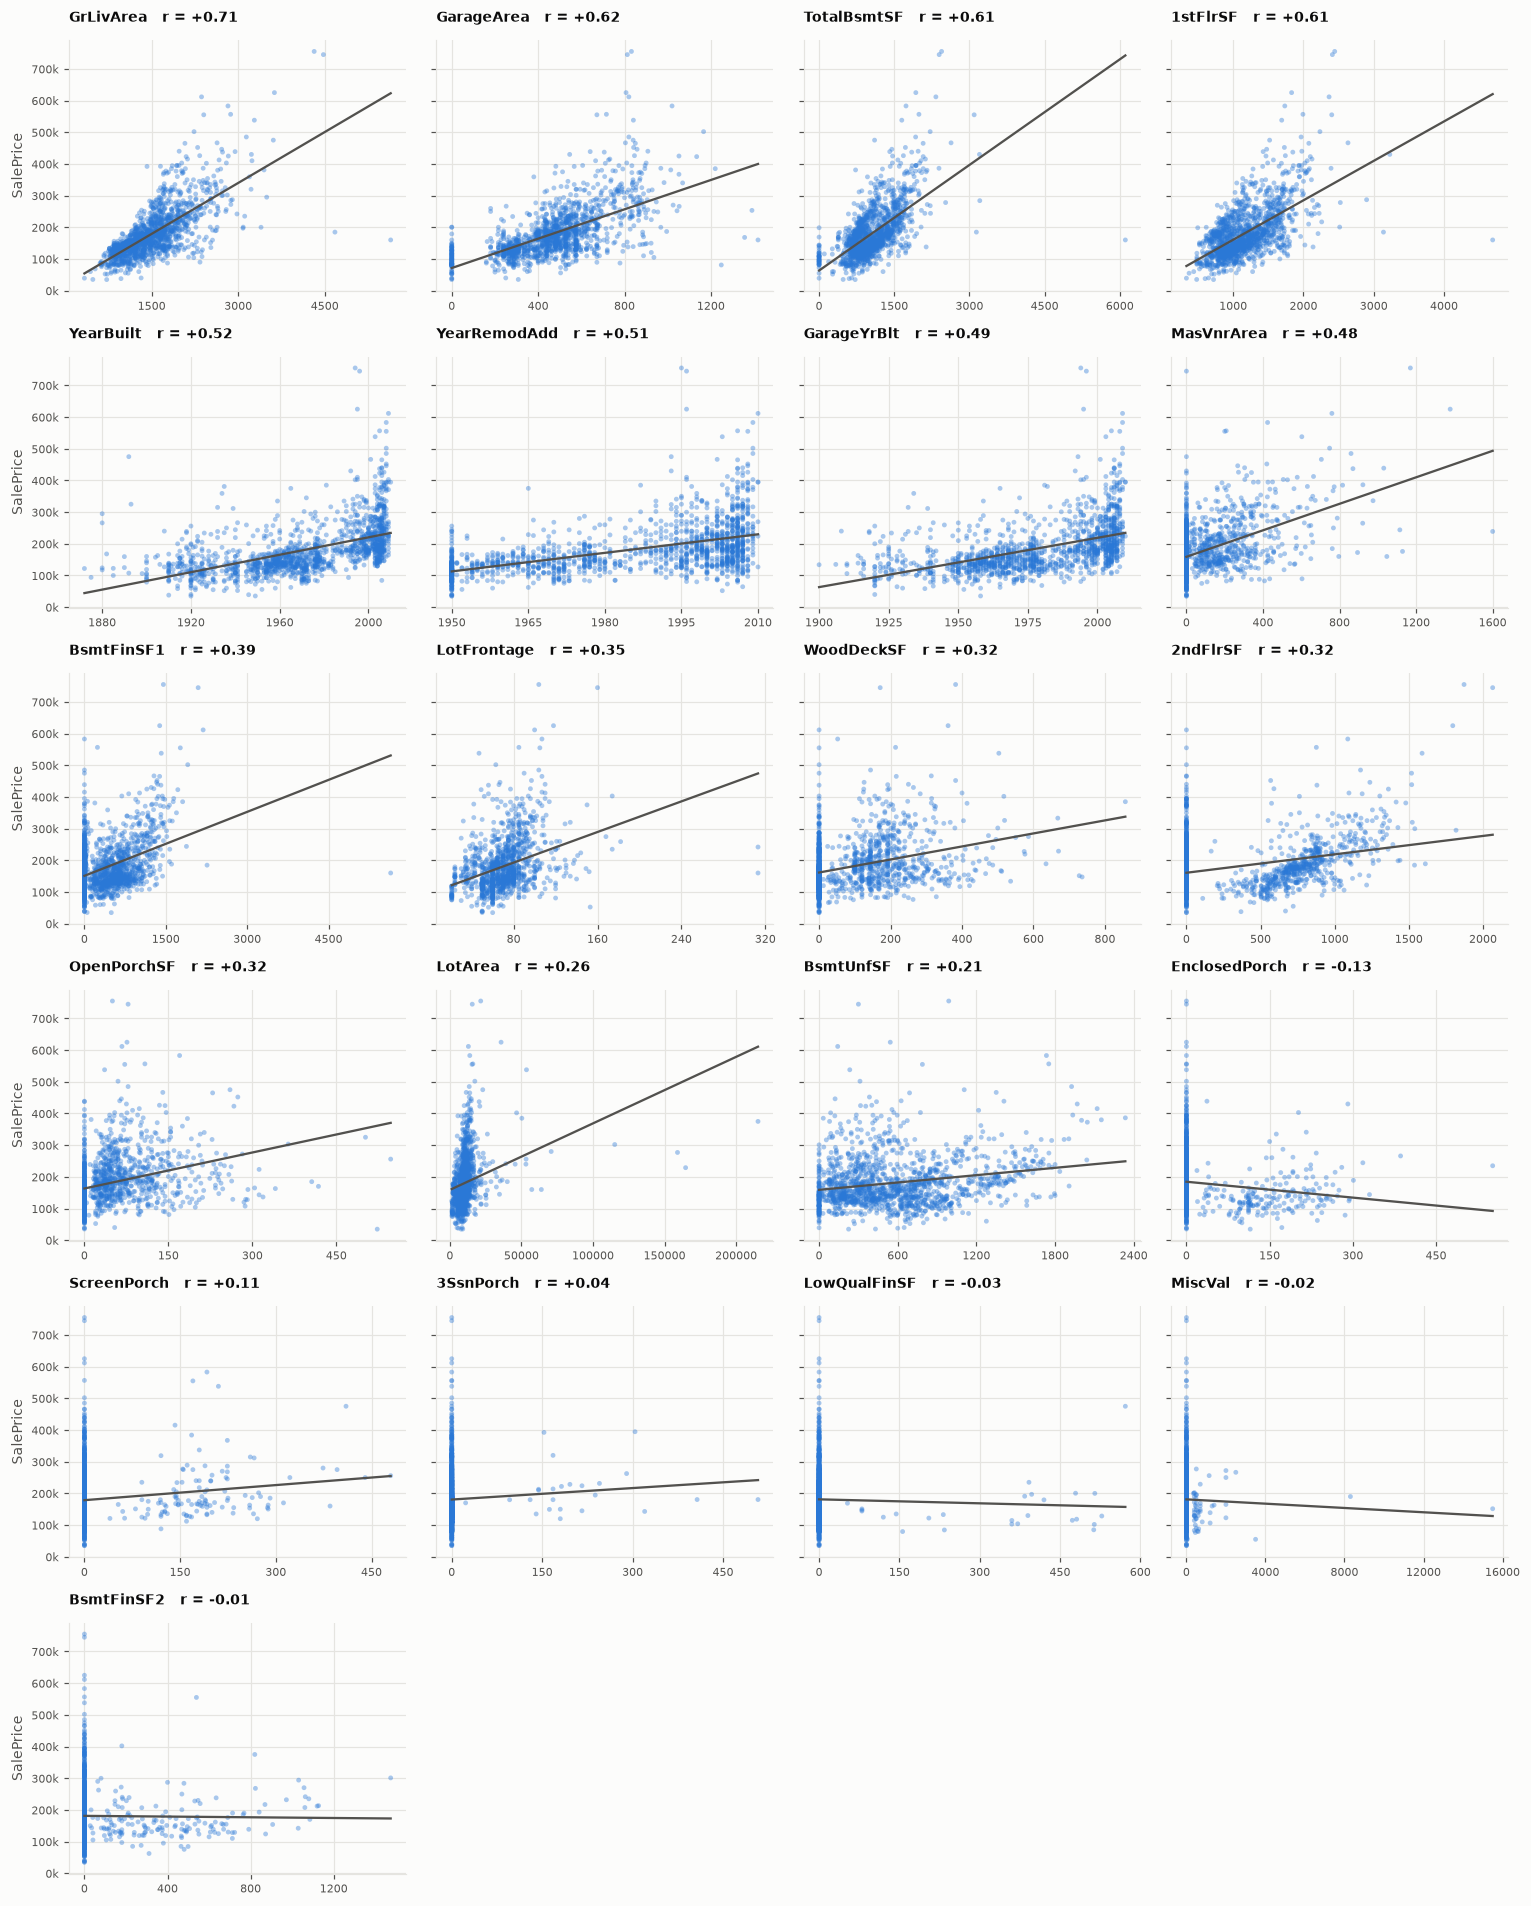

In [16]:
from matplotlib.ticker import MaxNLocator

orden = corrs[continuas].abs().sort_values(ascending=False).index.tolist()
N_COLS = 4
n_filas = -(-len(orden) // N_COLS)  # división entera hacia arriba

fig, axes = plt.subplots(n_filas, N_COLS, figsize=(14, 2.9 * n_filas), sharey=True)
paneles = axes.flatten()

for ax, col in zip(paneles, orden):
    ax.scatter(train[col], y, s=10, color=BLUE, alpha=0.4, edgecolor="none")

    # Línea de tendencia: delata si la relación es lineal o si r engaña.
    datos = train[[col]].assign(_precio=y).dropna()
    if len(datos) > 1 and datos[col].nunique() > 1:
        pendiente, intercepto = np.polyfit(datos[col], datos["_precio"], 1)
        xs = np.linspace(datos[col].min(), datos[col].max(), 50)
        ax.plot(xs, pendiente * xs + intercepto, color=INK_MUTED, linewidth=1.5)

    # Pocos ticks y enteros donde la variable lo es: con 4 paneles por fila,
    # los años salían encimados (2006.02006.5...).
    es_entero = bool(train[col].dropna().mod(1).eq(0).all())
    ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=es_entero))
    ax.set_title(f"{col}   r = {corrs[col]:+.2f}", fontsize=9)
    ax.tick_params(labelsize=7)
    ax.set_axisbelow(True)

for ax in paneles[len(orden) :]:
    ax.set_visible(False)

# Etiquetar solo la columna izquierda: repetirlo en cada panel sería ruido.
for ax in axes[:, 0]:
    ax.set_ylabel("SalePrice")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")

fig.tight_layout()

tabla_corr_continuas = (
    corrs[continuas]
    .sort_values(ascending=False)
    .rename("correlacion")
    .to_frame()
    .assign(abs_correlacion=lambda d: d["correlacion"].abs())
    .round(3)
)

print(f"{len(orden)} variables continuas · {n_filas}x{N_COLS} paneles")
tabla_corr_continuas


## 4.3 Boxplot de las variables discretas

Para las discretas, cada valor de la variable es una categoría en el eje X y el precio va en
el eje Y. El boxplot resume la distribución de cada nivel (mediana, cuartiles) y **encima se
dibujan los puntos individuales** con `stripplot`, desplazados horizontalmente al azar
(*jitter*) para que no se tapen entre sí.

Mostrar los puntos importa: un boxplot sobre un nivel con 5 casas se ve igual de sólido que
uno con 500, y es una diferencia enorme. Con los puntos a la vista, los niveles mal poblados
se delatan solos. Por eso los *outliers* del boxplot van apagados (`showfliers=False`): ya
están dibujados como puntos, y repetirlos duplicaría la misma marca.

Debajo de cada panel, el conteo de casas por nivel confirma cuáles son fiables.

Dos lecturas que conviene anticipar: `PoolArea` entra aquí por tener solo 8 valores distintos,
pero es engañosa — 1453 de las 1460 casas valen 0, así que los demás niveles son una casa o
dos. Y `MoSold` (mes de venta) debería salir plano: el mes no mueve el precio.

15 variables discretas · 5x3 paneles
niveles con menos de 10 casas: 24 de 106


,variable,nivel,casas
0,OverallQual,1,2
1,OverallQual,2,3
14,GarageCars,4,5
15,FullBath,0,9
19,TotRmsAbvGrd,2,1
30,TotRmsAbvGrd,14,1
34,Fireplaces,3,5
41,BsmtFullBath,3,1
42,BedroomAbvGr,0,6
48,BedroomAbvGr,6,7


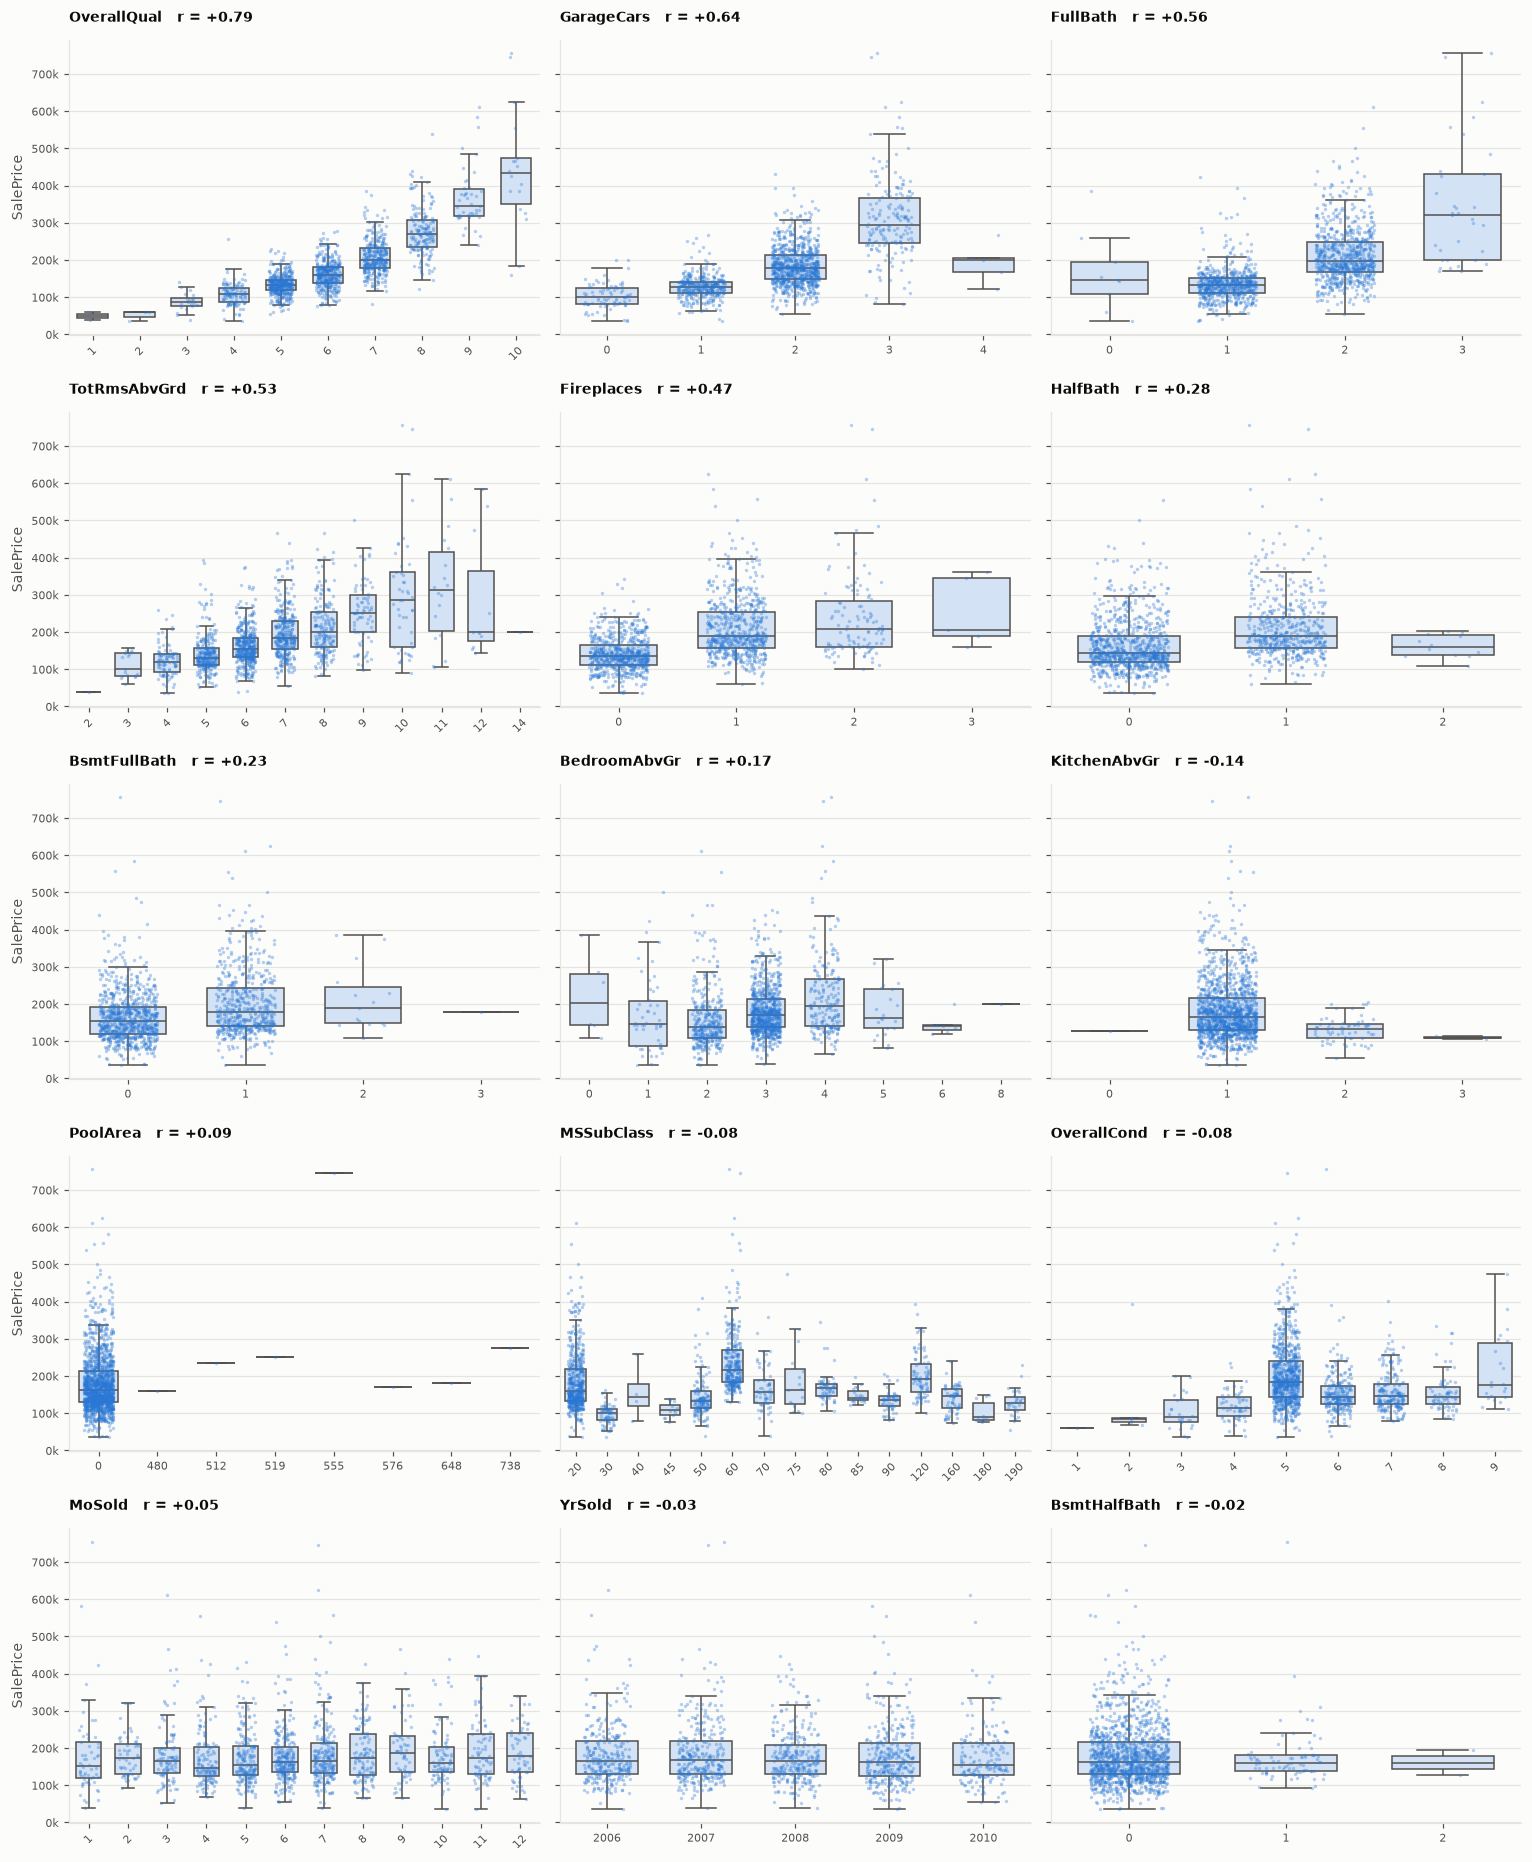

In [17]:
import seaborn as sns

orden_disc = corrs[discretas].abs().sort_values(ascending=False).index.tolist()
N_COLS_BOX = 3
n_filas_box = -(-len(orden_disc) // N_COLS_BOX)

AZUL_CLARO = "#cde2fb"  # relleno de las cajas: recesivo frente a los puntos

fig, axes = plt.subplots(
    n_filas_box, N_COLS_BOX, figsize=(14, 3.4 * n_filas_box), sharey=True
)
paneles = axes.flatten()

for ax, col in zip(paneles, orden_disc):
    niveles = sorted(train[col].dropna().unique())

    sns.boxplot(
        data=train, x=col, y="SalePrice", order=niveles, ax=ax,
        color=AZUL_CLARO, linecolor=INK_MUTED, linewidth=1,
        showfliers=False,  # los puntos ya los dibuja el stripplot
        width=0.65,
    )
    sns.stripplot(
        data=train, x=col, y="SalePrice", order=niveles, ax=ax,
        color=BLUE, size=2.2, alpha=0.35, jitter=0.25,
        linewidth=0,
    )

    ax.set_title(f"{col}   r = {corrs[col]:+.2f}", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(labelsize=7)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)
    if len(niveles) > 8:
        ax.tick_params(axis="x", rotation=45)

for ax in paneles[len(orden_disc) :]:
    ax.set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("SalePrice")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")

fig.tight_layout()

# Conteo por nivel: delata los niveles con tan pocas casas que su caja no significa nada.
conteos = (
    pd.concat(
        {c: train[c].value_counts().sort_index() for c in orden_disc},
        names=["variable", "nivel"],
    )
    .rename("casas")
    .reset_index()
)
escasos = conteos[conteos["casas"] < 10]

print(f"{len(orden_disc)} variables discretas · {n_filas_box}x{N_COLS_BOX} paneles")
print(f"niveles con menos de 10 casas: {len(escasos)} de {len(conteos)}")
escasos


## 5. Variables categóricas y ordinales

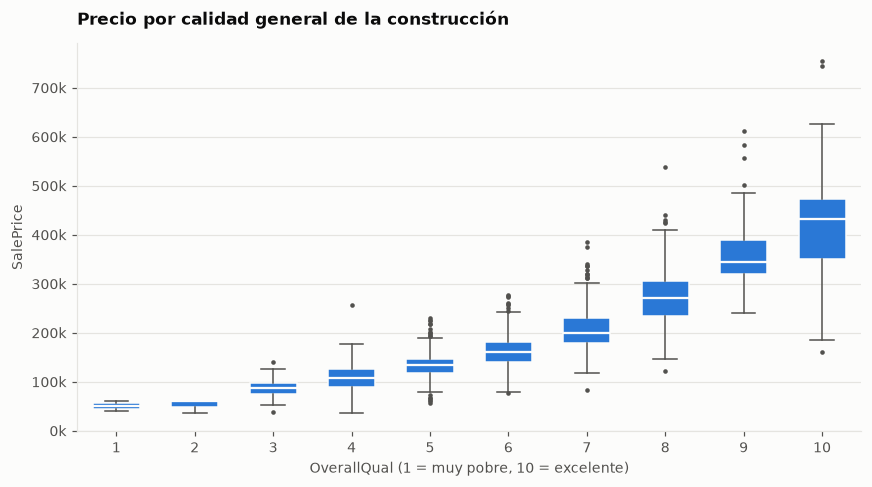

In [18]:
# OverallQual es ordinal (1-10): el boxplot muestra si la relación con el precio es monótona.
grupos = [y[train["OverallQual"] == q].values for q in sorted(train["OverallQual"].unique())]
etiquetas = sorted(train["OverallQual"].unique())

fig, ax = plt.subplots(figsize=(8, 4.5))
bp = ax.boxplot(
    grupos,
    tick_labels=etiquetas,
    patch_artist=True,
    widths=0.6,
    medianprops={"color": SURFACE, "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": INK_MUTED, "markeredgecolor": "none"},
    whiskerprops={"color": INK_MUTED, "linewidth": 1},
    capprops={"color": INK_MUTED, "linewidth": 1},
)
for caja in bp["boxes"]:
    caja.set(facecolor=BLUE, edgecolor=SURFACE, linewidth=1)

ax.set_title("Precio por calidad general de la construcción")
ax.set_xlabel("OverallQual (1 = muy pobre, 10 = excelente)")
ax.set_ylabel("SalePrice")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()

Neighborhood,MeadowV,IDOTRR,BrDale,OldTown,Edwards,BrkSide,Sawyer,Blueste,SWISU,NAmes,NPkVill,Mitchel,SawyerW,Gilbert,NWAmes,Blmngtn,CollgCr,ClearCr,Crawfor,Veenker,Somerst,Timber,StoneBr,NoRidge,NridgHt
median,88000.0,103000.0,106000.0,119000.0,121750.0,124300.0,135000.0,137500.0,139500.0,140000.0,146000.0,153500.0,179900.0,181000.0,182900.0,191000.0,197200.0,200250.0,200624.0,218000.0,225500.0,228475.0,278000.0,301500.0,315000.0
count,17.0,37.0,16.0,113.0,100.0,58.0,74.0,2.0,25.0,225.0,9.0,49.0,59.0,79.0,73.0,17.0,150.0,28.0,51.0,11.0,86.0,38.0,25.0,41.0,77.0


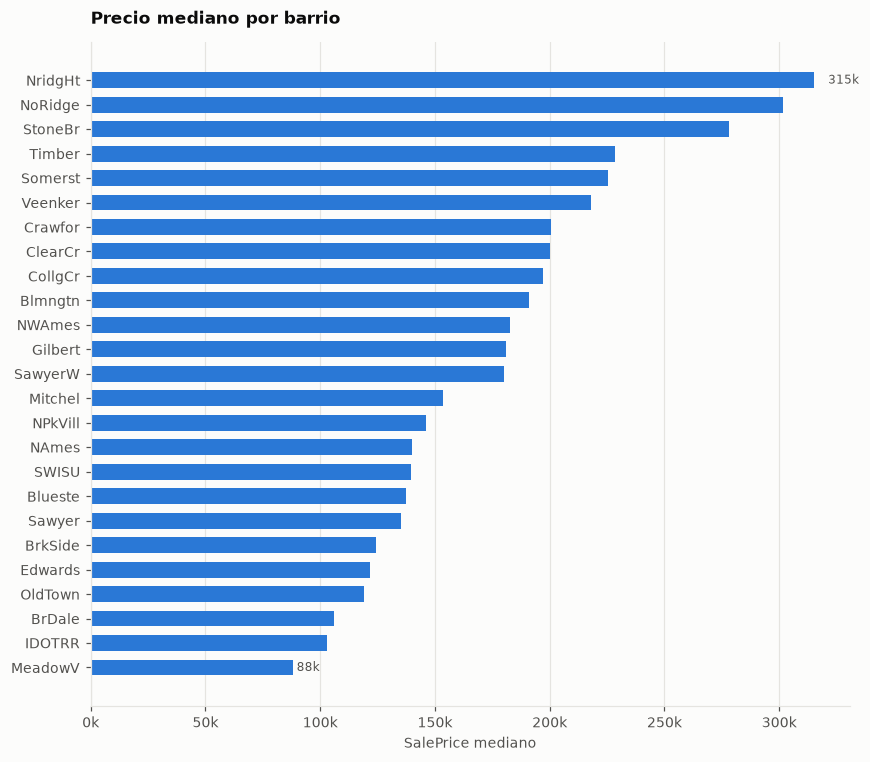

In [19]:
barrios = train.groupby("Neighborhood")["SalePrice"].agg(["median", "count"]).sort_values("median")

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(barrios.index, barrios["median"], color=BLUE, height=0.65)
ax.set_title("Precio mediano por barrio")
ax.set_xlabel("SalePrice mediano")
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)

# Solo los extremos llevan etiqueta directa; el resto se lee del eje.
for nombre in [barrios.index[0], barrios.index[-1]]:
    v = barrios.loc[nombre, "median"]
    ax.text(v * 1.02, nombre, f"{v / 1000:.0f}k", va="center", fontsize=8, color=INK_MUTED)

fig.tight_layout()
barrios.T

In [20]:
# Categóricas casi constantes: aportan poco y conviene marcarlas como candidatas a descarte.
dominancia = pd.DataFrame(
    {
        "niveles": train[cat_cols].nunique(),
        "nivel_dominante": train[cat_cols].apply(lambda s: s.mode(dropna=False).iloc[0]),
        "pct_dominante": (train[cat_cols].apply(lambda s: s.value_counts(dropna=False).iloc[0]) / len(train) * 100).round(1),
    }
)
dominancia.sort_values("pct_dominante", ascending=False).head(15)

,niveles,nivel_dominante,pct_dominante
Utilities,2,AllPub,99.9
Street,2,Pave,99.6
PoolQC,3,NaN,99.5
Condition2,8,Norm,99.0
RoofMatl,8,CompShg,98.2
Heating,6,GasA,97.8
MiscFeature,4,NaN,96.3
LandSlope,3,Gtl,94.7
Alley,2,NaN,93.8
CentralAir,2,Y,93.5


## 5.1 Todas las categóricas, ordenadas por η²

Pearson no sirve aquí: `Neighborhood` no tiene orden numérico, así que no existe una recta que
ajustar. La métrica equivalente para una variable categórica frente a un target continuo es
**η² (eta cuadrado)**, también llamada razón de correlación.

### Cómo funciona

η² parte la varianza del precio en dos y pregunta qué fracción explica la categoría:

$$\eta^2 = \frac{SS_{entre}}{SS_{total}}$$

- `SS_total` — cuánto se alejan todos los precios de la media global.
- `SS_entre` — cuánto se alejan las **medias de cada grupo** de esa media global.

Si todas las casas de un barrio costaran lo mismo y los barrios difirieran entre sí, `SS_entre`
sería igual a `SS_total` y η² daría 1. Si todos los barrios tuvieran la misma media, `SS_entre`
sería 0 y η² también.

**Se lee como la proporción de la varianza del precio que explica esa variable**, de 0 a 1.
`Neighborhood` con η² = 0.55 significa que el barrio, por sí solo, da cuenta del 55 % de la
variación de precios.

### Por qué es comparable con la correlación

Su raíz, **η**, vive en la misma escala que |r| — y no por analogía: cuando la variable tiene
solo dos niveles, η es *exactamente* igual al |r| de Pearson con una codificación 0/1. η es la
generalización de |r| a cualquier número de categorías. Por eso la tabla incluye las dos.

### Las dos trampas

**η² siempre sube al agregar niveles**, aunque sean ruido: con suficientes grupos, cada uno
termina capturando fluctuaciones aleatorias. La tabla incluye **ω² (omega cuadrado)**, que
descuenta esa inflación estimando cuánto explicaría una variable sin relación real. La brecha
`eta2 - omega2` mide el castigo; aquí es diminuta (0.009 en el peor caso) porque 1460 filas
sobran para 25 niveles, pero con muestras chicas puede ser enorme.

**η² no tiene signo.** Mide fuerza, no dirección — no existe "correlación negativa" cuando el
eje X no está ordenado. La dirección se lee en el gráfico, donde los niveles van ordenados por
mediana de precio.

El `p` del test F acompaña como control: dice si la diferencia entre grupos podría ser azar.

43 categóricas · 15x3 paneles
castigo máximo por nº de niveles (eta2 - omega2): 0.0089
sin diferencia significativa entre grupos (p > 0.05): ['LandSlope', 'Street', 'Utilities']


,eta2,omega2,niveles,p_valor,eta,castigo_niveles
Neighborhood,0.5456,0.5378,25,0.0000,0.7386,0.0078
ExterQual,0.4774,0.4761,4,0.0000,0.6909,0.0012
BsmtQual,0.4650,0.4634,5,0.0000,0.6819,0.0016
KitchenQual,0.4566,0.4553,4,0.0000,0.6757,0.0013
GarageFinish,0.3059,0.3043,4,0.0000,0.5531,0.0016
FireplaceQu,0.2940,0.2914,6,0.0000,0.5422,0.0026
Foundation,0.2564,0.2537,6,0.0000,0.5063,0.0027
GarageType,0.2492,0.2460,7,0.0000,0.4992,0.0032
BsmtFinType1,0.2108,0.2074,7,0.0000,0.4591,0.0034
HeatingQC,0.1955,0.1932,5,0.0000,0.4422,0.0023


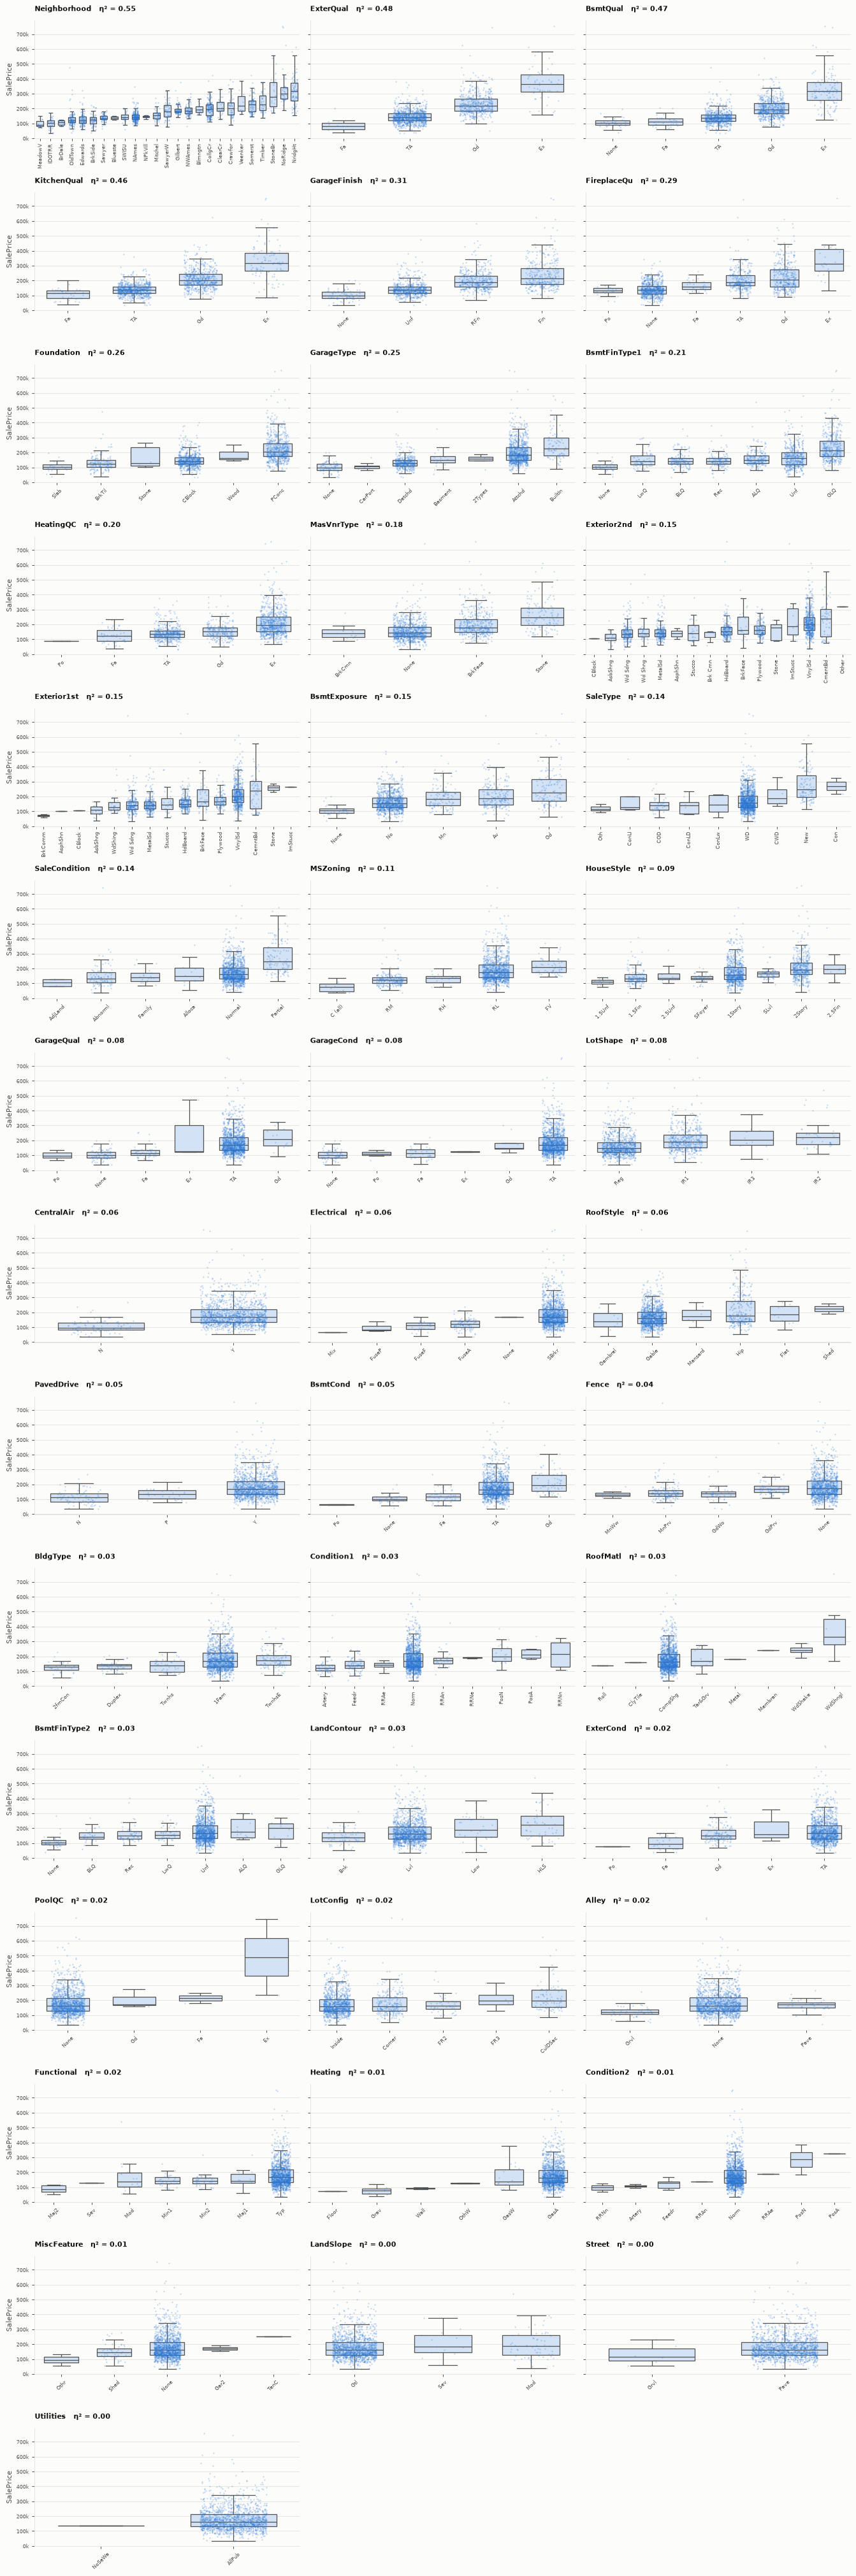

In [21]:
from scipy import stats

cat_cols_todas = train.select_dtypes(exclude="number").columns.tolist()


def fuerza_asociacion(serie, objetivo):
    """η², ω², número de niveles y p del test F para una categórica contra un target continuo."""
    g = serie.fillna("None")
    grupos = [objetivo[g == nivel].to_numpy() for nivel in g.unique()]
    n, k = len(objetivo), len(grupos)

    media = objetivo.mean()
    ss_total = ((objetivo - media) ** 2).sum()
    ss_entre = sum(len(gr) * (gr.mean() - media) ** 2 for gr in grupos)
    ms_dentro = (ss_total - ss_entre) / (n - k)

    eta2 = ss_entre / ss_total
    # ω² descuenta la inflación que produce tener muchos niveles.
    omega2 = (ss_entre - (k - 1) * ms_dentro) / (ss_total + ms_dentro)
    p = stats.f_oneway(*grupos).pvalue
    return eta2, omega2, k, p


tabla_eta = (
    pd.DataFrame(
        {c: fuerza_asociacion(train[c], y) for c in cat_cols_todas},
        index=["eta2", "omega2", "niveles", "p_valor"],
    )
    .T.assign(
        eta=lambda d: np.sqrt(d["eta2"]),
        castigo_niveles=lambda d: d["eta2"] - d["omega2"],
        niveles=lambda d: d["niveles"].astype(int),
    )
    .sort_values("eta2", ascending=False)
    .round(4)
)

# --- Rejilla de boxplots, de mayor a menor η² ---
orden_cat = tabla_eta.index.tolist()
N_COLS_CAT = 3
n_filas_cat = -(-len(orden_cat) // N_COLS_CAT)

fig, axes = plt.subplots(
    n_filas_cat, N_COLS_CAT, figsize=(15, 3.0 * n_filas_cat), dpi=90, sharey=True
)
paneles = axes.flatten()

for ax, col in zip(paneles, orden_cat):
    datos = train.assign(**{col: train[col].fillna("None")})
    # Niveles ordenados por mediana: sin orden natural, esto hace legible la tendencia.
    niveles = datos.groupby(col)["SalePrice"].median().sort_values().index.tolist()

    sns.boxplot(
        data=datos, x=col, y="SalePrice", order=niveles, ax=ax,
        color=AZUL_CLARO, linecolor=INK_MUTED, linewidth=1,
        showfliers=False, width=0.65,
    )
    sns.stripplot(
        data=datos, x=col, y="SalePrice", order=niveles, ax=ax,
        color=BLUE, size=1.8, alpha=0.3, jitter=0.25, linewidth=0,
    )

    ax.set_title(f"{col}   η² = {tabla_eta.loc[col, 'eta2']:.2f}", fontsize=9)
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.tick_params(labelsize=6)
    ax.tick_params(axis="x", rotation=90 if len(niveles) > 8 else 45)
    ax.grid(axis="x", visible=False)
    ax.set_axisbelow(True)

for ax in paneles[len(orden_cat) :]:
    ax.set_visible(False)

for ax in axes[:, 0]:
    ax.set_ylabel("SalePrice")
    ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")

fig.tight_layout()

sin_senal = tabla_eta[tabla_eta["p_valor"] > 0.05]
print(f"{len(orden_cat)} categóricas · {n_filas_cat}x{N_COLS_CAT} paneles")
print(f"castigo máximo por nº de niveles (eta2 - omega2): {tabla_eta['castigo_niveles'].max():.4f}")
print(f"sin diferencia significativa entre grupos (p > 0.05): {list(sin_senal.index)}")
tabla_eta


## 6. Hallazgos y siguientes pasos

Completa esta sección con lo que veas al ejecutar el notebook. Puntos a confirmar:

- **Objetivo sesgado a la derecha.** Si `log1p(SalePrice)` se acerca a sesgo 0, entrenar sobre el log.
- **Faltantes estructurales.** Separar "sin la característica" (`PoolQC`, `Alley`, `Fence`, `*Garage*`,
  `*Bsmt*`) de faltantes reales (`LotFrontage`, `Electrical`). Las primeras se imputan con una
  categoría `"None"` o `0`; las segundas, con mediana o moda por barrio.
- **Redundancia entre predictoras.** Revisar pares muy correlacionados entre sí
  (`GarageCars`/`GarageArea`, `TotalBsmtSF`/`1stFlrSF`, `TotRmsAbvGrd`/`GrLivArea`).
- **Outliers de `GrLivArea`.** Decidir si se excluyen las casas grandes y baratas o se tratan
  vía `SaleCondition`.
- **Columnas casi constantes** (`Utilities`, `Street`, `PoolQC`…): candidatas a descarte.

Lo que se decida aquí se implementa en `house_pricing/features.py`, para que el notebook
quede como bitácora y no como código de producción.